# Segmentation: pixel measures, tiles and empty images

A segmentation is a binary classification of every pixel, so the measures of the package apply to it
directly. What changes is the *unit* that gets averaged. A metric can be pooled over all pixels, or computed
per image and then averaged, and the choice is the micro-versus-macro choice of notebook 02 with images in
place of classes. This notebook uses real microscopy images and three deliberately simple segmenters to
look at four things: how much pixel accuracy says when most pixels are background, whether pooled and
per-image IoU agree, what happens to images that contain no object at all, and what pixel measures cannot
see.

The notebook does not rank segmentation methods. The three methods are thresholds, chosen to be easy to
read and to fail in different ways.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from aggmetrics import IndicatorMatrix

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## The data

**BBBC039** (Caicedo et al., 2019; Broad Bioimage Benchmark Collection) holds fluorescence images of U2OS cell
nuclei with every nucleus annotated by hand, released under CC0. The repository bundles a derived subset:
12 fields from the official test split, each cropped to 384 by 512 pixels and rescaled to 8 bits. The
processing is described in `examples/data/bbbc039/README.md`. The annotation has the value 0 for background
and 1 to 3 for the nuclei (touching nuclei get different values), so that nuclei can be counted later.

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/bbbc039/subset.npz"
local = Path("../data/bbbc039/subset.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
with np.load(source) as z:
    images, labels = z["images"], z["labels"]
truth = labels > 0
print("fields, rows, columns:", images.shape)
print("foreground share of the 12 fields:", truth.mean().round(3))

fields, rows, columns: (12, 384, 512)
foreground share of the 12 fields: 0.182


## Three segmenters

All three smooth the image with a Gaussian of width 1 pixel and then threshold it.

- `otsu`: one global threshold per image, chosen by Otsu's method.
- `local`: a pixel is foreground if it exceeds the mean of its 41 by 41 neighbourhood by 4 grey levels.
- `low`: a global threshold at half of Otsu's, which marks the dim halo around each nucleus as foreground.

A fourth predictor, `all background`, predicts no foreground anywhere. It is the reference that any
measure of a segmentation should be able to reject.

In [4]:
def otsu(x):
    # threshold that maximises the between-class variance of the 256-bin histogram
    h, _ = np.histogram(x, bins=256, range=(0, 255))
    p = h / h.sum()
    w, mu = np.cumsum(p), np.cumsum(p * np.arange(256))
    return float(np.argmax((mu[-1] * w - mu) ** 2 / (w * (1 - w) + 1e-12)))

def smooth(img):
    return ndi.gaussian_filter(img.astype(float), 1)

def seg_otsu(img):
    g = smooth(img)
    return g > otsu(g)

def seg_local(img, window=41, offset=4):
    g = smooth(img)
    return g > ndi.uniform_filter(g, window) + offset

def seg_low(img):
    return smooth(img) > 0.5 * otsu(img)

methods = {"otsu": seg_otsu, "local": seg_local, "low": seg_low}
pred = {k: np.stack([f(x) for x in images]) for k, f in methods.items()}
pred["all background"] = np.zeros_like(pred["otsu"])
print("foreground share, truth:", truth.mean().round(3))
for k, v in pred.items():
    print(f"  {k:15s}", v.mean().round(3))

foreground share, truth: 0.182
  otsu            0.174
  local           0.187
  low             0.213
  all background  0.0


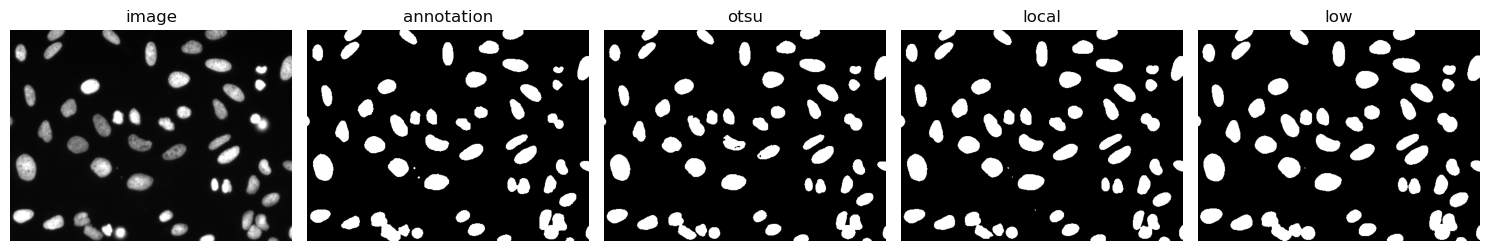

In [5]:
field = 3
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
ax[0].imshow(images[field], cmap="gray"); ax[0].set_title("image")
ax[1].imshow(truth[field], cmap="gray"); ax[1].set_title("annotation")
for a, k in zip(ax[2:], ["otsu", "local", "low"]):
    a.imshow(pred[k][field], cmap="gray"); a.set_title(k)
for a in ax:
    a.axis("off"); a.grid(False)
plt.tight_layout(); plt.show()

## One column per tile

The package takes a matrix with one column per label, so the layout has to be chosen. Here each image is cut
into 128 by 128 tiles (12 fields give 144 tiles) and **each tile is a column**, with its 16,384 pixels as the
rows, as a multilabel problem. Then the micro operator pools all pixels, and the macro operator computes the
measure tile by tile and averages, with the convention for undefined entries applying to tiles that have
nothing to measure. The weighted operator weights each tile by its number of foreground pixels.

Pixel accuracy first, next to the other pooled measures.

In [6]:
def tiles(x, size=128):
    n, h, w = x.shape
    return x.reshape(n, h // size, size, w // size, size).transpose(0, 1, 3, 2, 4).reshape(-1, size * size)

Y = tiles(truth).astype(int).T                       # (pixels in a tile, tiles): one column per tile
P = {k: tiles(v).astype(int).T for k, v in pred.items()}
ims = {k: IndicatorMatrix(Y, v, task="multilabel") for k, v in P.items()}
print("tiles:", Y.shape[1], "| pixels per tile:", Y.shape[0])
print("tiles with no foreground in the annotation:", int((Y.sum(axis=0) == 0).sum()))

tiles: 144 | pixels per tile: 16384
tiles with no foreground in the annotation: 4


In [7]:
rows = {}
for k, im in ims.items():
    rows[k] = {
        "pixel accuracy": im.compute("label_accuracy", "micro"),
        "specificity": im.compute("specificity", "micro"),
        "recall": im.compute("recall", "micro"),
        "precision": im.compute("precision", "micro"),
        "IoU, pooled": im.compute("jaccard", "micro"),
        "Dice, pooled": im.compute("f1", "micro"),
    }
table = pd.DataFrame(rows).round(4)
table

,otsu,local,low,all background
pixel accuracy,0.9850,0.9817,0.9682,0.8181
specificity,0.9954,0.9855,0.9617,1.0000
recall,0.9381,0.9643,0.9972,0.0000
precision,0.9784,0.9368,0.8528,NaN
"IoU, pooled",0.9191,0.9054,0.8508,0.0000
"Dice, pooled",0.9579,0.9503,0.9194,0.0000


Pixel accuracy is 0.818 for the predictor that outputs nothing, and 0.968 to 0.985 for the three
segmenters. The whole range of useful segmenters sits in the last 0.18 of the scale, and the worst of them,
`low`, is 0.15 above the trivial one. Recall ranks the segmenters in the opposite order to IoU: `low` has
recall 0.997 and the lowest IoU, because it labels the halo of every nucleus as foreground. A measure that
ignores one of the two error types is maximised by predicting everything, as in notebook 07.

IoU and Dice are zero for `all background`, as they should be. They are the better choice here, and the
question is now which average of them to report.

## Pooled, per tile and weighted

In [8]:
rows = {}
for k, im in ims.items():
    rows[k] = {
        "IoU pooled (micro)": im.compute("jaccard", "micro"),
        "IoU per tile (macro)": im.compute("jaccard", "macro"),
        "IoU weighted by foreground": im.compute("jaccard", "weighted"),
        "Dice pooled (micro)": im.compute("f1", "micro"),
        "Dice per tile (macro)": im.compute("f1", "macro"),
    }
pd.DataFrame(rows).round(4)

,otsu,local,low,all background
IoU pooled (micro),0.9191,0.9054,0.8508,0.0
IoU per tile (macro),0.9165,0.8841,0.8296,0.0
IoU weighted by foreground,0.9192,0.9059,0.8523,0.0
Dice pooled (micro),0.9579,0.9503,0.9194,0.0
Dice per tile (macro),0.9556,0.9327,0.9014,0.0


The ranking `otsu`, `local`, `low` is the same under all five variants, so for these three methods the
choice of operator does not change the verdict. It changes the numbers. For `otsu` the pooled and per-tile IoU
differ by 0.003, and for `local` and `low` by 0.021 (0.9054 against 0.8841, and 0.8508 against 0.8296): the
per-tile mean is lower for them, which means that some tiles are segmented worse than the pool suggests. The
weighted IoU is within 0.002 of the pooled one for every method, as expected when the weights are the tile
foreground sizes.

## Tiles with nothing to segment

Four of the 144 tiles contain no nucleus. For a method that also predicts nothing there, the per-tile IoU is
0/0. The package leaves the choice to the caller (`convention`): `exclude` drops the tile, `zero` scores it 0
and `one` scores it 1. The column `undefined tiles` counts them, and a method that predicts something in an
empty tile gets an IoU of 0 there, defined, which is why `local` and `low` have three undefined tiles
and not four.

In [9]:
rows = {}
for k, im in ims.items():
    parts = im.parts("jaccard", "macro")
    rows[k] = {
        "undefined tiles": int(np.isnan(parts).sum()),
        "exclude": im.compute("jaccard", "macro", convention="exclude"),
        "zero": im.compute("jaccard", "macro", convention="zero"),
        "one": im.compute("jaccard", "macro", convention="one"),
    }
pd.DataFrame(rows).T.round(4)

,undefined tiles,exclude,zero,one
otsu,4.0,0.9165,0.8911,0.9188
local,3.0,0.8841,0.8657,0.8865
low,3.0,0.8296,0.8124,0.8332
all background,4.0,0.0000,0.0000,0.0278


The convention moves the mean per-tile IoU of `otsu` between 0.8911 and 0.9188, a spread of 0.028, which is
about the gap between `otsu` and `local` under `exclude` (0.032). Under `one`, the predictor that outputs
nothing scores 0.028, a positive score for doing nothing, earned from the four empty tiles. None of this
reverses the order of the segmenters, and none of it can be decided from the data: it is a choice about what
an empty image should count for, and it should be reported.

## Where the per-tile average goes down

The per-tile mean is lower for `local` and `low` because of small tiles. Splitting the tiles by foreground
share shows the pattern. The pooled measure sees only the pixels, and the tiles with under 5% foreground hold
under 1% of them.

In [10]:
share = Y.mean(axis=0)
edges = [0.0001, 0.05, 0.15, 0.30]
names = ["empty", "< 5%", "5-15%", "15-30%", "> 30%"]
bin_of = np.digitize(share, edges)
summary = pd.DataFrame({
    "tiles": np.bincount(bin_of, minlength=5),
    "share of all foreground pixels": [Y[:, bin_of == b].sum() / Y.sum() for b in range(5)],
}, index=names).round(3)
iou_tile = {k: ims[k].parts("jaccard", "macro") for k in ("otsu", "local", "low")}
for k, v in iou_tile.items():
    summary[f"mean IoU, {k}"] = [np.nanmean(v[bin_of == b]) if (~np.isnan(v[bin_of == b])).any() else np.nan for b in range(5)]
summary.round(3)

,tiles,share of all foreground pixels,"mean IoU, otsu","mean IoU, local","mean IoU, low"
empty,4,0.000,NaN,0.000,0.000
< 5%,10,0.008,0.902,0.716,0.663
5-15%,36,0.153,0.905,0.889,0.835
15-30%,84,0.709,0.922,0.910,0.853
> 30%,10,0.129,0.927,0.904,0.859


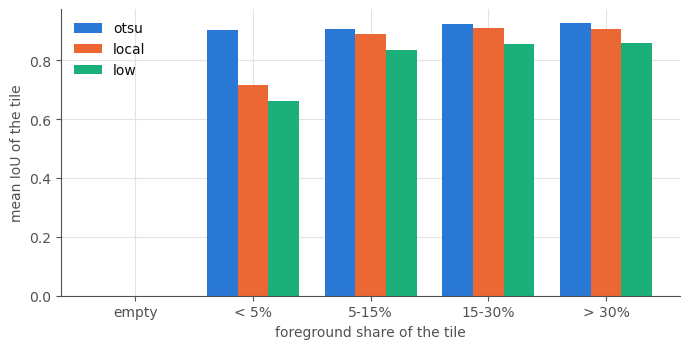

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.6))
width = 0.26
for i, (k, c) in enumerate(zip(["otsu", "local", "low"], [BLUE, ORANGE, AQUA])):
    ax.bar(np.arange(5) + (i - 1) * width, summary[f"mean IoU, {k}"].fillna(0), width, color=c, label=k)
ax.set_xticks(range(5)); ax.set_xticklabels(names)
ax.set_xlabel("foreground share of the tile"); ax.set_ylabel("mean IoU of the tile")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

In the tiles with under 5% foreground, `local` reaches a mean IoU of 0.716 and `low` 0.663, against
0.902 for `otsu`, while in the tiles above 15% all three are within 0.07 of each other. A pooled IoU is
dominated by the large tiles and hides this; the per-tile mean shows it, and the empty tiles (IoU 0 for `local`
and `low` in the first row of the table, where one empty tile has false positives) are the extreme case. Which
of the two is the right number depends on whether a small field of view matters as much as a crowded one.

## What a pixel measure cannot see

A segmentation is usually a step towards counting or measuring objects. The annotation holds 768 nuclei. The
number of connected components in each prediction is below.

In [12]:
def count_true(lab):
    return sum(ndi.label(lab == v)[1] for v in (1, 2, 3))

n_true = int(sum(count_true(l) for l in labels))
print("nuclei in the 12 fields:", n_true)
for k in ("otsu", "local", "low"):
    n_pred = int(sum(ndi.label(m)[1] for m in pred[k]))
    print(f"  {k:6s} connected components: {n_pred:4d}   pooled IoU {ims[k].compute('jaccard', 'micro'):.4f}")

nuclei in the 12 fields: 768
  otsu   connected components:  643   pooled IoU 0.9191
  local  connected components:  719   pooled IoU 0.9054
  low    connected components:  613   pooled IoU 0.8508


`otsu` has the highest IoU and 643 components against 768 nuclei, and `local` has a lower IoU and the
count closest to the truth (719). The count is not an accuracy: a method can split some nuclei and merge others
and land on the right total. The point is the other direction. A pixel IoU of 0.92 is compatible with a
component count that is off by a sixth, so a pixel measure cannot say whether touching nuclei were
separated. Object-level measures (matching predicted and annotated objects, as in Panoptic Quality) address
that and are not covered by this package.

## Summary

- Pixel accuracy compresses the differences between segmenters into the last 0.18 of its scale and gives
  0.818 to a predictor that outputs nothing. Use a measure that is zero for it, such as IoU or Dice.
- Pooling pixels and averaging per image are different measures. Here they rank the methods alike and
  differ by up to 0.02, and the difference comes from images with little foreground.
- Images with no object make the per-image mean undefined, and the convention for them moves the number
  by as much as the gap between two of the methods. Report it.
- The tile layout (one column per tile) is a modelling choice, so `diagnose` findings that compare operators
  across columns, such as the exemplar check, are not meaningful for it.